# Auspify Data Science Internship – Netflix Dataset
Tasks completed: **1 Data Cleaning, 2 EDA, 3 Recommendation System, 4 Trend Prediction**

## Task 1 – Data Cleaning & Preprocessing

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
df = pd.read_csv('Dataset.csv')
print(df.shape); df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
print('Nulls:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate titles:', df.duplicated(['title','type','release_year']).sum())
for c in df.select_dtypes('object'):
    n = df[c].astype(str).str.strip().str.lower().isin(['', 'unknown', 'nan', 'none', 'n/a']).sum()
    print(c, 'placeholder/blank:', n)

Nulls:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64
Duplicate rows: 0
Duplicate titles: 3
show_id placeholder/blank: 0
type placeholder/blank: 0
title placeholder/blank: 1
director placeholder/blank: 0
country placeholder/blank: 0
date_added placeholder/blank: 0
rating placeholder/blank: 0
duration placeholder/blank: 0
listed_in placeholder/blank: 0


In [3]:
df = df.drop_duplicates(['title','type','release_year']).copy()
for c in ['title','director','country','rating','duration','listed_in']:
    df[c] = df[c].astype(str).str.strip()
    df[c] = df[c].replace({'':np.nan,'nan':np.nan,'Unknown':np.nan})
df['director'] = df['director'].fillna('Unknown')
df['country']  = df['country'].fillna('Unknown')
df['rating']   = df['rating'].fillna(df['rating'].mode()[0])
df = df.dropna(subset=['duration','date_added'])
print(df.isna().sum())

show_id         0
type            0
title           1
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [4]:
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added']  = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()
df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['movie_min'] = np.where(df['type']=='Movie', df['duration_num'], np.nan)
df['seasons']   = np.where(df['type']=='TV Show', df['duration_num'], np.nan)
df['main_country'] = df['country'].str.split(',').str[0].str.strip()
df['genres'] = df['listed_in'].str.split(',').apply(lambda g: [x.strip() for x in g])
df['n_genres'] = df['genres'].str.len()
grp = {'TV-Y':'Kids','TV-Y7':'Kids','TV-G':'Kids','G':'Kids','TV-PG':'Older Kids','PG':'Older Kids',
       'TV-14':'Teens','PG-13':'Teens','TV-MA':'Adults','R':'Adults','NC-17':'Adults'}
df['audience'] = df['rating'].map(grp).fillna('Other')
df['type_code'] = df['type'].map({'Movie':0,'TV Show':1})

In [5]:
df.drop(columns=['genres']).to_csv('netflix_cleaned.csv', index=False)
print(df.shape); df.head()

(8787, 20)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_num,movie_min,seasons,main_country,genres,n_genres,audience,type_code
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90.0,90.0,NaN,United States,[Documentaries],1,Teens,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1.0,NaN,1.0,France,"[Crime TV Shows, International TV Shows, TV Ac...",3,Adults,1
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1.0,NaN,1.0,United States,"[TV Dramas, TV Horror, TV Mysteries]",3,Adults,1
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,September,91.0,91.0,NaN,Brazil,"[Children & Family Movies, Comedies]",2,Older Kids,0
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,September,125.0,125.0,NaN,United States,"[Dramas, Independent Movies, International Mov...",3,Adults,0


## Task 2 – Exploratory Data Analysis

In [6]:
print(df.info()); df[['release_year','year_added','movie_min','seasons','n_genres']].describe()

<class 'pandas.DataFrame'>
Index: 8787 entries, 0 to 8789
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8787 non-null   str           
 1   type          8787 non-null   str           
 2   title         8786 non-null   str           
 3   director      8787 non-null   str           
 4   country       8787 non-null   str           
 5   date_added    8787 non-null   datetime64[us]
 6   release_year  8787 non-null   int64         
 7   rating        8787 non-null   str           
 8   duration      8787 non-null   str           
 9   listed_in     8787 non-null   str           
 10  year_added    8787 non-null   int32         
 11  month_added   8787 non-null   str           
 12  duration_num  8787 non-null   float64       
 13  movie_min     6124 non-null   float64       
 14  seasons       2663 non-null   float64       
 15  main_country  8787 non-null   object        
 16  genr

,release_year,year_added,movie_min,seasons,n_genres
count,8787.000000,8787.000000,6124.000000,2663.000000,8787.000000
mean,2014.181746,2018.873677,99.573645,1.752159,2.194947
std,8.826635,1.573808,28.280425,1.550844,0.784195
min,1925.000000,2008.000000,3.000000,1.000000,1.000000
25%,2013.000000,2018.000000,87.000000,1.000000,2.000000
50%,2017.000000,2019.000000,98.000000,1.000000,2.000000
75%,2019.000000,2020.000000,114.000000,2.000000,3.000000
max,2021.000000,2021.000000,312.000000,17.000000,3.000000


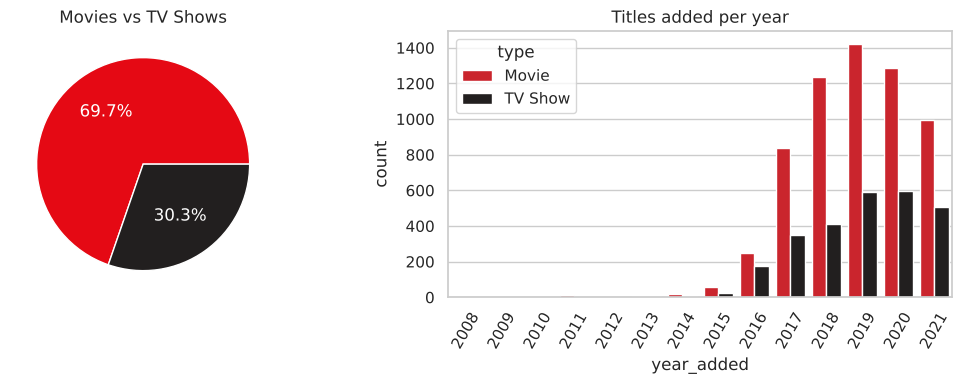

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
tc = df['type'].value_counts()
ax[0].pie(tc, labels=tc.index, autopct='%1.1f%%', colors=['#E50914','#221F1F'], textprops={'color':'w'})
ax[0].set_title('Movies vs TV Shows')
sns.countplot(data=df, x='year_added', hue='type', palette=['#E50914','#221F1F'], ax=ax[1])
ax[1].set_title('Titles added per year'); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.savefig('eda_type.png', dpi=150); plt.show()

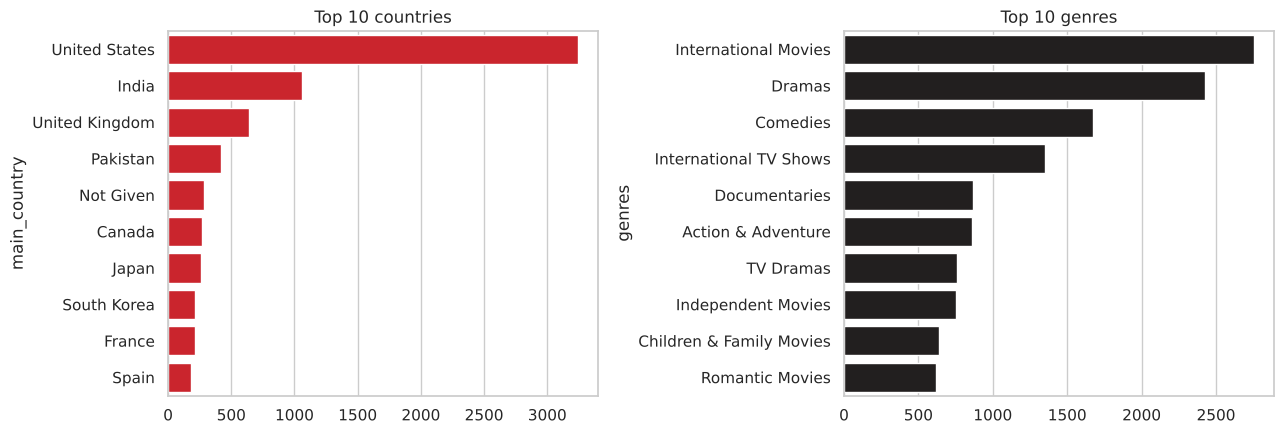

In [8]:
known = df[df['main_country']!='Unknown']
top_c = known['main_country'].value_counts().head(10)
top_g = df.explode('genres')['genres'].value_counts().head(10)
fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
sns.barplot(x=top_c.values, y=top_c.index, color='#E50914', ax=ax[0]); ax[0].set_title('Top 10 countries')
sns.barplot(x=top_g.values, y=top_g.index, color='#221F1F', ax=ax[1]); ax[1].set_title('Top 10 genres')
plt.tight_layout(); plt.savefig('eda_country_genre.png', dpi=150); plt.show()

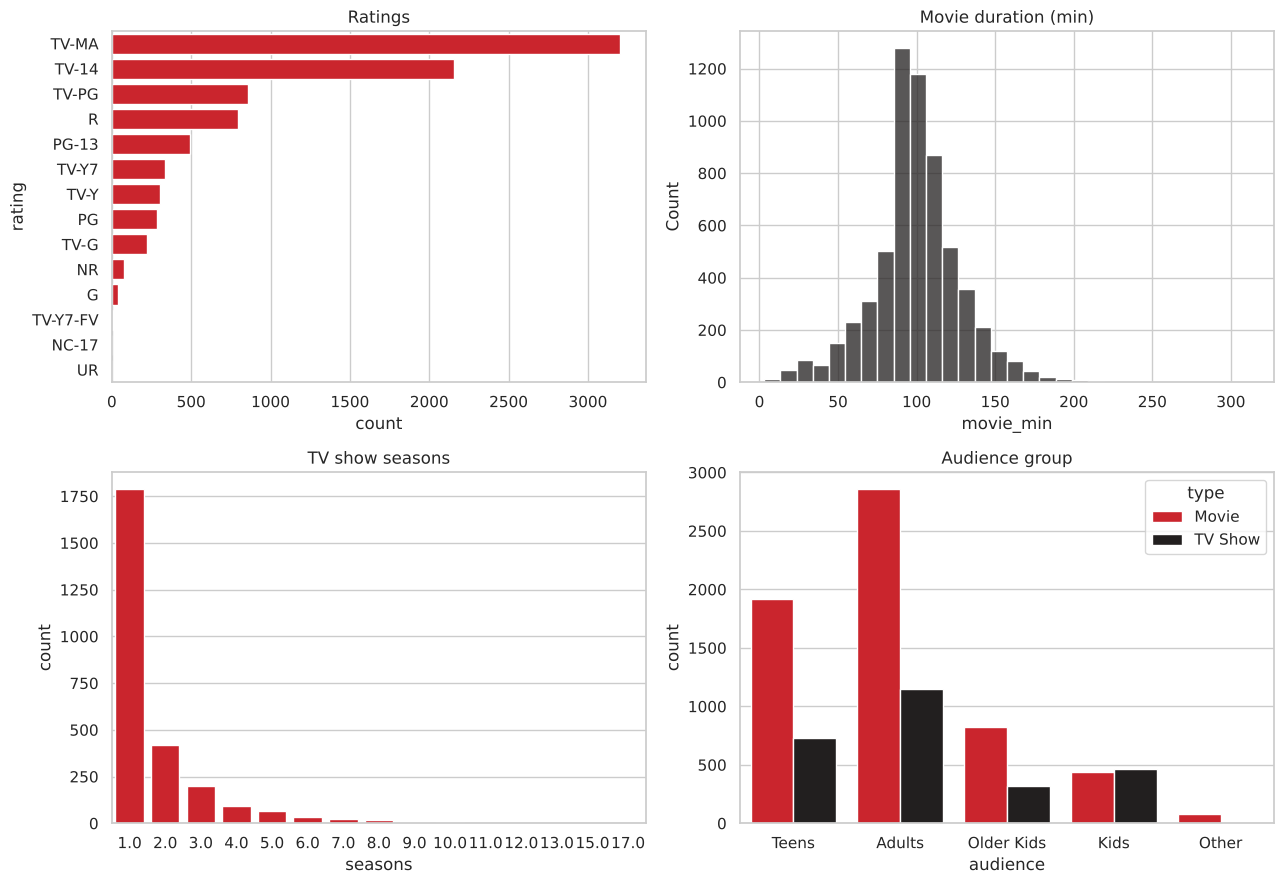

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13,9))
sns.countplot(data=df, y='rating', order=df['rating'].value_counts().index, color='#E50914', ax=ax[0,0]); ax[0,0].set_title('Ratings')
sns.histplot(df['movie_min'].dropna(), bins=30, color='#221F1F', ax=ax[0,1]); ax[0,1].set_title('Movie duration (min)')
sns.countplot(data=df[df.type=='TV Show'], x='seasons', color='#E50914', ax=ax[1,0]); ax[1,0].set_title('TV show seasons')
sns.countplot(data=df, x='audience', hue='type', palette=['#E50914','#221F1F'], ax=ax[1,1]); ax[1,1].set_title('Audience group')
plt.tight_layout(); plt.savefig('eda_metrics.png', dpi=150); plt.show()

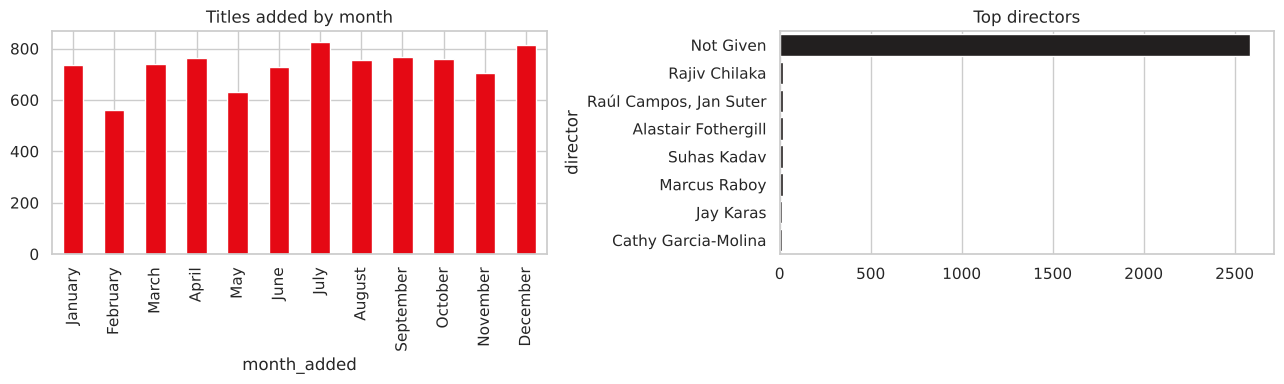

In [10]:
m = df['month_added'].value_counts().reindex(['January','February','March','April','May','June','July','August','September','October','November','December'])
d = df[df.director!='Unknown']['director'].value_counts().head(8)
fig, ax = plt.subplots(1, 2, figsize=(13,4))
m.plot.bar(color='#E50914', ax=ax[0]); ax[0].set_title('Titles added by month')
sns.barplot(x=d.values, y=d.index, color='#221F1F', ax=ax[1]); ax[1].set_title('Top directors')
plt.tight_layout(); plt.savefig('eda_month_director.png', dpi=150); plt.show()

In [11]:
print(f"Total titles: {len(df)} | Movies {tc['Movie']/len(df):.1%} | TV Shows {tc['TV Show']/len(df):.1%}")
print('Top country:', top_c.index[0], '| Top genre:', top_g.index[0])
print('Most common rating:', df.rating.mode()[0])
print('Median movie length:', df.movie_min.median(), 'min | Median seasons:', df.seasons.median())
print('Peak year added:', df.year_added.value_counts().idxmax(), '| Peak month:', m.idxmax())

Total titles: 8787 | Movies 69.7% | TV Shows 30.3%
Top country: United States | Top genre: International Movies
Most common rating: TV-MA
Median movie length: 98.0 min | Median seasons: 1.0
Peak year added: 2019 | Peak month: July


**Findings**
- Movies make up roughly 70% of the catalogue; TV shows ~30%.
- The United States leads by a wide margin, followed by India and the UK.
- International Movies, Dramas and Comedies are the most common genres.
- TV-MA and TV-14 dominate, so the catalogue is mainly aimed at teens and adults.
- Most movies run 90–110 min; most TV shows have only 1 season.
- Additions grew sharply until ~2019 and dipped afterwards.

## Task 3 – Recommendation System (content-based)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re
r = df.reset_index(drop=True)
def clean(s): return re.sub(r'[^a-z0-9 ]', '', s.lower().replace(' ', ''))
def soup(x):
    parts  = [x['type'].replace(' ','')]
    parts += [clean(g) for g in x['genres']] * 3
    parts += [clean(c) for c in x['country'].split(',')]
    parts += [clean(d) for d in x['director'].split(',')]
    parts += [clean(x['rating'])]
    return ' '.join(parts)
r['soup'] = r.apply(soup, axis=1)
r['soup'][:3].tolist()

['Movie documentaries documentaries documentaries unitedstates kirstenjohnson pg13',
 'TVShow crimetvshows internationaltvshows tvactionadventure crimetvshows internationaltvshows tvactionadventure crimetvshows internationaltvshows tvactionadventure france julienleclercq tvma',
 'TVShow tvdramas tvhorror tvmysteries tvdramas tvhorror tvmysteries tvdramas tvhorror tvmysteries unitedstates mikeflanagan tvma']

In [13]:
tf  = TfidfVectorizer()
X   = tf.fit_transform(r['soup'])
sim = cosine_similarity(X, dense_output=False)
idx = pd.Series(r.index, index=r['title'].str.lower())
print(X.shape)

(8787, 5127)


In [14]:
def recommend(title, n=5):
    i = idx[title.lower()]
    if isinstance(i, pd.Series): i = i.iloc[0]
    s = sim[i].toarray().ravel()
    top = s.argsort()[::-1][1:n+1]
    out = r.loc[top, ['title','type','listed_in','country','rating']].copy()
    out['score'] = s[top].round(3)
    return out
for t in ['Ganglands', 'Midnight Mass', 'Motu Patlu in Wonderland']:
    print('\n>>', t); display(recommend(t))


>> Ganglands


,title,type,listed_in,country,rating,score
8405,Crime Time,TV Show,"Crime TV Shows, International TV Shows, TV Act...",France,TV-MA,0.923
6735,Lupin,TV Show,"Crime TV Shows, International TV Shows, TV Act...",France,TV-MA,0.923
575,Fatal Destiny,TV Show,"Crime TV Shows, International TV Shows, TV Act...",Pakistan,TV-MA,0.885
8331,Agent Raghav,TV Show,"Crime TV Shows, International TV Shows, TV Act...",India,TV-14,0.881
7969,Smoking,TV Show,"Crime TV Shows, International TV Shows, TV Act...",Japan,TV-MA,0.881



>> Midnight Mass


,title,type,listed_in,country,rating,score
7073,Ratched,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA,0.949
7907,The Haunting of Hill House,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA,0.949
7043,The Haunting of Bly Manor,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA,0.949
6616,Brand New Cherry Flavor,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA,0.949
7959,The Originals,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-14,0.942



>> Motu Patlu in Wonderland


,title,type,listed_in,country,rating,score
1063,Motu Patlu in Hong Kong: Kung Fu Kings 3,Movie,"Children & Family Movies, Music & Musicals",India,TV-Y7,1.000
1066,Motu Patlu Kung Fu Kings 4 The Challenge of Ku...,Movie,"Children & Family Movies, Music & Musicals",India,TV-Y7,1.000
1065,Motu Patlu in the City of Gold,Movie,"Children & Family Movies, Comedies, Music & Mu...",India,TV-Y7,0.921
7,Motu Patlu in the Game of Zones,Movie,"Children & Family Movies, Comedies, Music & Mu...",India,TV-Y7,0.921
5473,"Monster High: Boo York, Boo York",Movie,"Children & Family Movies, Music & Musicals",United States,TV-Y7,0.816


In [15]:
rng = np.random.RandomState(42)
sample = rng.choice(len(r), 300, replace=False)
jac, same, rnd = [], [], []
for i in sample:
    g = set(r.genres[i]); s = sim[i].toarray().ravel()
    top = s.argsort()[::-1][1:6]
    jac.append(np.mean([len(g & set(r.genres[j]))/len(g | set(r.genres[j])) for j in top]))
    same.append(np.mean([r.type[j]==r.type[i] for j in top]))
    rj = rng.choice(len(r), 5)
    rnd.append(np.mean([len(g & set(r.genres[j]))/len(g | set(r.genres[j])) for j in rj]))
print(f'Avg genre overlap (recommended): {np.mean(jac):.3f}')
print(f'Avg genre overlap (random baseline): {np.mean(rnd):.3f}')
print(f'Same-type rate: {np.mean(same):.1%}')

Avg genre overlap (recommended): 0.958
Avg genre overlap (random baseline): 0.098
Same-type rate: 99.9%


The model recommends titles with much higher genre overlap than a random baseline and almost always the same type (movie/show). Limitation: the dataset has no descriptions or user ratings, so this is content-based only.

## Task 4 – Trend Prediction Analysis

In [16]:
from statsmodels.tsa.holtwinters import Holt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
y = df[(df.release_year>=2000)&(df.release_year<=2020)].groupby('release_year').size()
print(y.tail(8))

release_year
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
dtype: int64


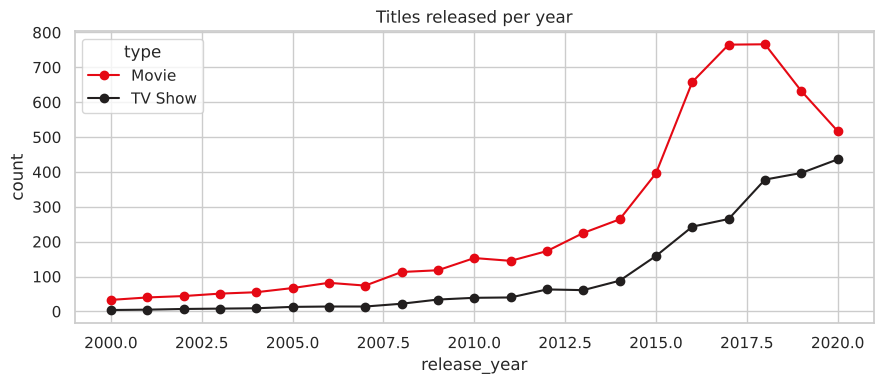

In [17]:
t = df[(df.release_year>=2000)&(df.release_year<=2020)].groupby(['release_year','type']).size().unstack(fill_value=0)
t.plot(figsize=(9,4), color=['#E50914','#221F1F'], marker='o', title='Titles released per year')
plt.ylabel('count'); plt.tight_layout(); plt.savefig('trend_type.png', dpi=150); plt.show()

In [18]:
tr, te = y[:-4], y[-4:]
def lin(train, steps, deg=2):
    X = np.arange(len(train)).reshape(-1,1)
    P = lambda a: np.hstack([a**k for k in range(1,deg+1)])
    m = LinearRegression().fit(P(X), train.values)
    f = np.arange(len(train), len(train)+steps).reshape(-1,1)
    return m.predict(P(f))
preds = {
  'Linear':     lin(tr, 4, 1),
  'Polynomial': lin(tr, 4, 2),
  'Holt':       Holt(tr.values.astype(float), damped_trend=True, initialization_method='estimated').fit().forecast(4),
}
rows = []
for k,p in preds.items():
    rows.append([k, mean_absolute_error(te,p), np.sqrt(mean_squared_error(te,p))])
res = pd.DataFrame(rows, columns=['model','MAE','RMSE']).round(1)
res

,model,MAE,RMSE
0,Linear,454.4,464.7
1,Polynomial,183.7,203.5
2,Holt,718.4,833.9


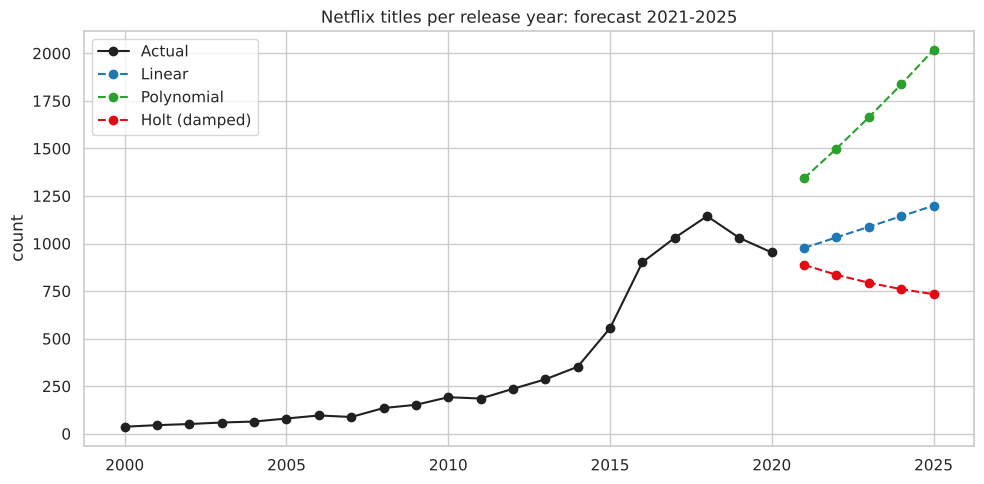

,Linear,Polynomial,Holt (damped)
2021,977.0,1344.0,888.0
2022,1032.0,1499.0,835.0
2023,1088.0,1664.0,794.0
2024,1144.0,1837.0,760.0
2025,1199.0,2018.0,734.0


In [19]:
h = 5; fy = np.arange(2021, 2021+h)
fc = {
  'Linear':     lin(y, h, 1),
  'Polynomial': lin(y, h, 2),
  'Holt (damped)': Holt(y.values.astype(float), damped_trend=True, initialization_method='estimated').fit().forecast(h),
}
plt.figure(figsize=(10,5))
plt.plot(y.index, y.values, 'o-', color='#221F1F', label='Actual')
for (k,v),c in zip(fc.items(), ['#1f77b4','#2ca02c','#E50914']):
    plt.plot(fy, np.clip(v,0,None), '--o', color=c, label=k)
plt.title('Netflix titles per release year: forecast 2021-2025'); plt.legend(); plt.ylabel('count')
plt.tight_layout(); plt.savefig('trend_forecast.png', dpi=150); plt.show()
pd.DataFrame({k:np.clip(v,0,None).round() for k,v in fc.items()}, index=fy)

In [20]:
best = res.sort_values('RMSE').iloc[0]['model']
print('Best model on validation:', best)
print('Peak year:', y.idxmax(), 'with', y.max(), 'titles')

Best model on validation: Polynomial
Peak year: 2018 with 1144 titles


**Interpretation**
- Content releases grew almost exponentially from ~2010, peaking around 2018 and then falling.
- Because of the 2018 peak and 2020 drop (COVID-19 production slowdown, plus this dataset only covers titles added up to 2021), pure trend models are uncertain.
- Linear/polynomial models extrapolate the growth; the damped Holt model gives the most conservative forecast. Use the validation table above to pick the best.
- Forecasts are indicative only; a 21-point yearly series is small.